In [ ]:
import os
os.getcwd()


'/content'

In [ ]:
os.chdir('/content/drive/MyDrive')
os.getcwd()


'/content/drive/MyDrive'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn import preprocessing
from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings('ignore')

In [ ]:
import pandas as pd

data = pd.read_csv('/content/StudentsPerformance (1).csv')

In [ ]:
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [ ]:
data.isna().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


<Axes: >

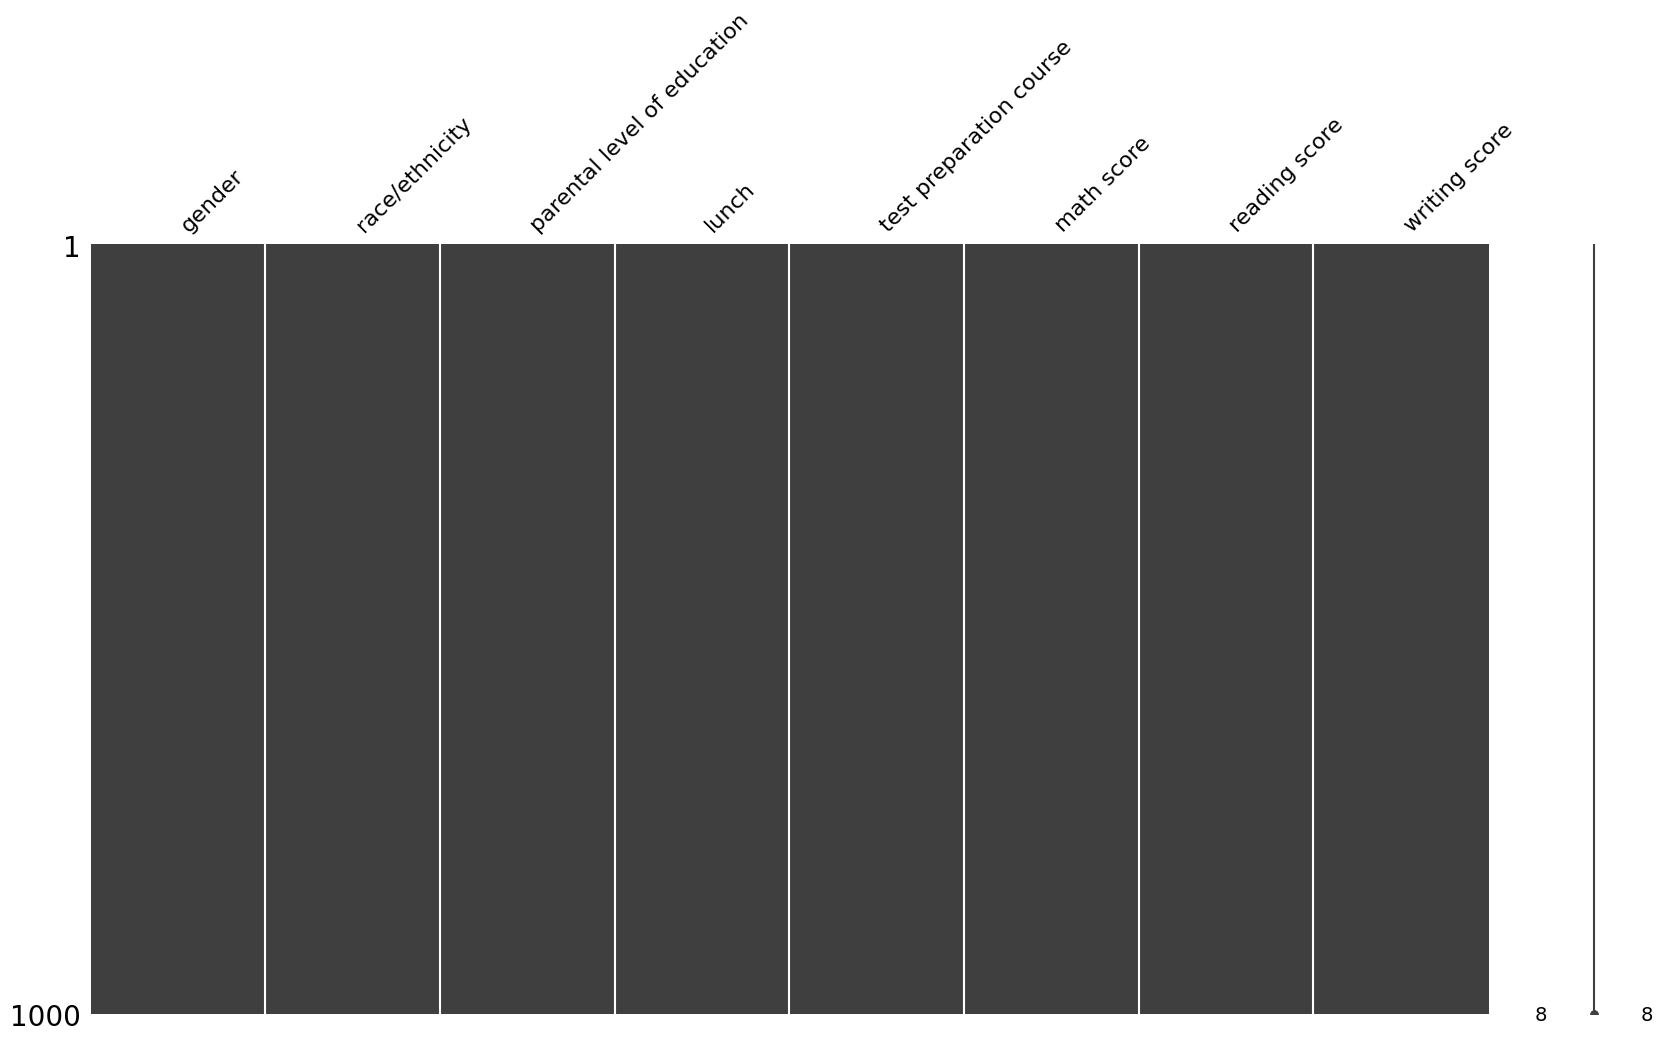

In [ ]:
import missingno as msno
msno.matrix(data,figsize=(20, 10))

In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
# Number of Unique values in each column
data.nunique()

,0
gender,2
race/ethnicity,5
parental level of education,6
lunch,2
test preparation course,2
math score,81
reading score,72
writing score,77


In [ ]:
data.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [ ]:
# Frequency of each item in (gender, race/ethnicity , parental level of education , lunch , test preparation course )
col = ['gender', 'race/ethnicity' ,'parental level of education' ,'lunch' ,'test preparation course']
for i in col:
  print(data[i].value_counts())
  print('____________________________________________________________________')

gender
female    518
male      482
Name: count, dtype: int64
____________________________________________________________________
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64
____________________________________________________________________
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64
____________________________________________________________________
lunch
standard        645
free/reduced    355
Name: count, dtype: int64
____________________________________________________________________
test preparation course
none         642
completed    358
Name: count, dtype: int64
____________________________________________________________________


In [ ]:
import os
os.listdir('/content')


['.config', 'sample_data']

In [ ]:
 import pandas as pd
 data = pd.read_csv('/content/StudentsPerformance (1).csv')
# Number of males/females in each group in race/ethnicity column
data.groupby(['race/ethnicity', 'gender']).size()

race/ethnicity  gender
group A         female     36
                male       53
group B         female    104
                male       86
group C         female    180
                male      139
group D         female    129
                male      133
group E         female     69
                male       71
dtype: int64

In [ ]:
data.groupby(['race/ethnicity','parental level of education']).size()

race/ethnicity  parental level of education
group A         associate's degree             14
                bachelor's degree              12
                high school                    18
                master's degree                 3
                some college                   18
                some high school               24
group B         associate's degree             41
                bachelor's degree              20
                high school                    48
                master's degree                 6
                some college                   37
                some high school               38
group C         associate's degree             78
                bachelor's degree              40
                high school                    64
                master's degree                19
                some college                   69
                some high school               49
group D         associate's degree             50
                bachelor's degree              28
                high school                    44
                master's degree                23
                some college                   67
                some high school               50
group E         associate's degree             39
                bachelor's degree              18
                high school                    22
                master's degree                 8
                some college                   35
                some high school               18
dtype: int64

In [ ]:
# Number of students in each type of lunch in each group
data.groupby(['lunch','race/ethnicity']).size()

lunch         race/ethnicity
free/reduced  group A            36
              group B            69
              group C           114
              group D            95
              group E            41
standard      group A            53
              group B           121
              group C           205
              group D           167
              group E            99
dtype: int64

In [ ]:
# Number of students in each type of lunch in Gender
data.groupby(['lunch','gender']).size()

lunch         gender
free/reduced  female    189
              male      166
standard      female    329
              male      316
dtype: int64

In [ ]:
# Number of students who completed and didn't complete the test preparation course in each group
data.groupby(['race/ethnicity','test preparation course']).size()

race/ethnicity  test preparation course
group A         completed                   31
                none                        58
group B         completed                   68
                none                       122
group C         completed                  117
                none                       202
group D         completed                   82
                none                       180
group E         completed                   60
                none                        80
dtype: int64

In [ ]:
# students who have 100 points In every subject
data[(data['math score'] == 100) & (data['reading score'] == 100) & (data['writing score'] == 100)]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
458,female,group E,bachelor's degree,standard,none,100,100,100
916,male,group E,bachelor's degree,standard,completed,100,100,100
962,female,group E,associate's degree,standard,none,100,100,100


In [ ]:
# students who have 100 points in math score
data[data['math score'] == 100]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
149,male,group E,associate's degree,free/reduced,completed,100,100,93
451,female,group E,some college,standard,none,100,92,97
458,female,group E,bachelor's degree,standard,none,100,100,100
623,male,group A,some college,standard,completed,100,96,86
625,male,group D,some college,standard,completed,100,97,99
916,male,group E,bachelor's degree,standard,completed,100,100,100
962,female,group E,associate's degree,standard,none,100,100,100


In [ ]:
# students who have 100 points in reading score
data[data['reading score'] == 100]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
106,female,group D,master's degree,standard,none,87,100,100
114,female,group E,bachelor's degree,standard,completed,99,100,100
149,male,group E,associate's degree,free/reduced,completed,100,100,93
165,female,group C,bachelor's degree,standard,completed,96,100,100
179,female,group D,some high school,standard,completed,97,100,100
381,male,group C,associate's degree,standard,completed,87,100,95
458,female,group E,bachelor's degree,standard,none,100,100,100
546,female,group A,some high school,standard,completed,92,100,97
566,female,group E,bachelor's degree,free/reduced,completed,92,100,100
594,female,group C,bachelor's degree,standard,completed,92,100,99


In [ ]:
# students who have 100 points in writing score
data[data['writing score'] == 100]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
106,female,group D,master's degree,standard,none,87,100,100
114,female,group E,bachelor's degree,standard,completed,99,100,100
165,female,group C,bachelor's degree,standard,completed,96,100,100
179,female,group D,some high school,standard,completed,97,100,100
377,female,group D,master's degree,free/reduced,completed,85,95,100
403,female,group D,high school,standard,completed,88,99,100
458,female,group E,bachelor's degree,standard,none,100,100,100
566,female,group E,bachelor's degree,free/reduced,completed,92,100,100
685,female,group E,master's degree,standard,completed,94,99,100
903,female,group D,bachelor's degree,free/reduced,completed,93,100,100


In [ ]:
#students who have 0 point in any subject
data[(data['math score'] == 0) | (data['reading score'] == 0) | (data['writing score'] == 0)]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
59,female,group C,some high school,free/reduced,none,0,17,10


In [ ]:
# relationship between writing score less than 50 and complete test preparation course
data[(data['writing score'] < 50) & (data['test preparation course'])]['test preparation course'].value_counts()

,count
test preparation course,
none,98
completed,16


In [ ]:
data['Percentage'] = (data['math score'] + data['reading score'] + data['writing score']) / 3

In [ ]:
def Grade(Percentage):
    if (Percentage >= 95):return 'A+'
    if (Percentage >= 90):return 'A'
    if (Percentage >= 80):return 'B'
    if (Percentage >= 70):return 'C+'
    if (Percentage >= 60):return 'C'
    if (Percentage >= 50):return 'D'
    else: return 'F'

In [ ]:
data['Grade'] = data['Percentage'].apply(Grade)

In [ ]:
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Percentage,Grade
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,C+
1,female,group C,some college,standard,completed,69,90,88,82.333333,B
2,female,group B,master's degree,standard,none,90,95,93,92.666667,A
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,F
4,male,group C,some college,standard,none,76,78,75,76.333333,C+


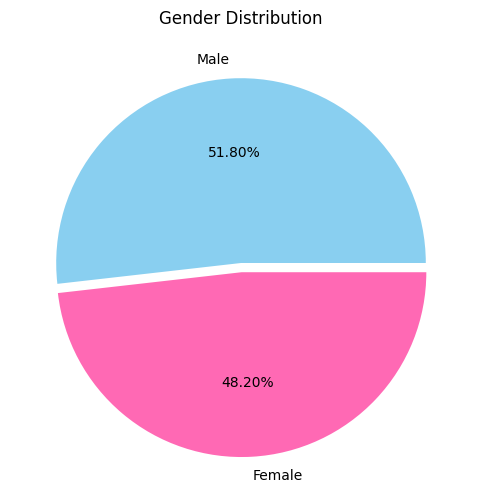

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
labeles=['Male','Female']
plt.pie(data['gender'].value_counts(),labels=labeles,autopct='%1.2f%%',colors=["#89CFF0", "#FF69B4"],explode=(0,0.05))
plt.title('Gender Distribution')
plt.show()

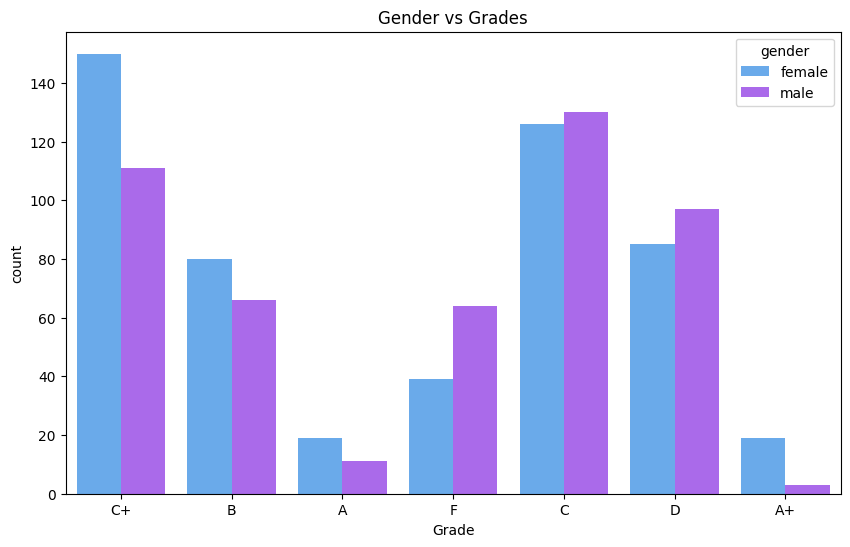

In [ ]:
# Gender vs Grades
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.countplot(x='Grade', hue='gender', data=data, palette='cool')
plt.title('Gender vs Grades')
plt.show()

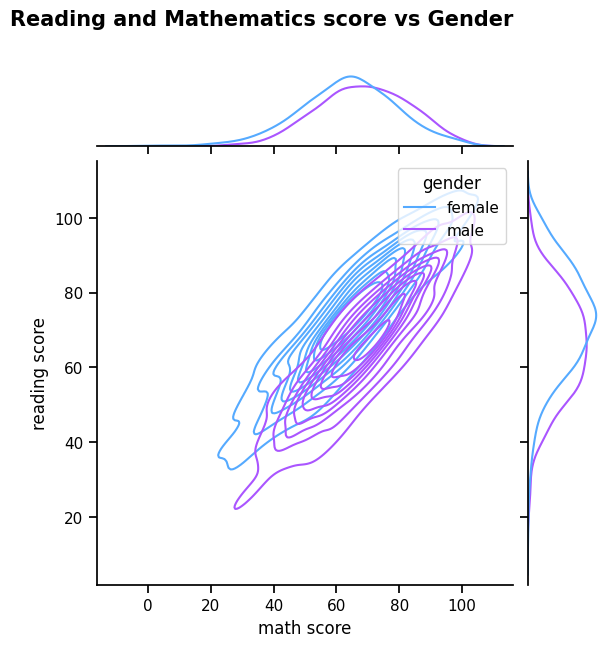

In [ ]:
# see the relationship between reading and mathematical score and their gender distribution
sns.set_context("notebook")
sns.jointplot(data=data, x="math score", y="reading score", hue="gender", kind="kde",palette='cool')
plt.title('Reading and Mathematics score vs Gender', fontsize=15, fontweight='bold',y=1.3,loc="right")
plt.show()

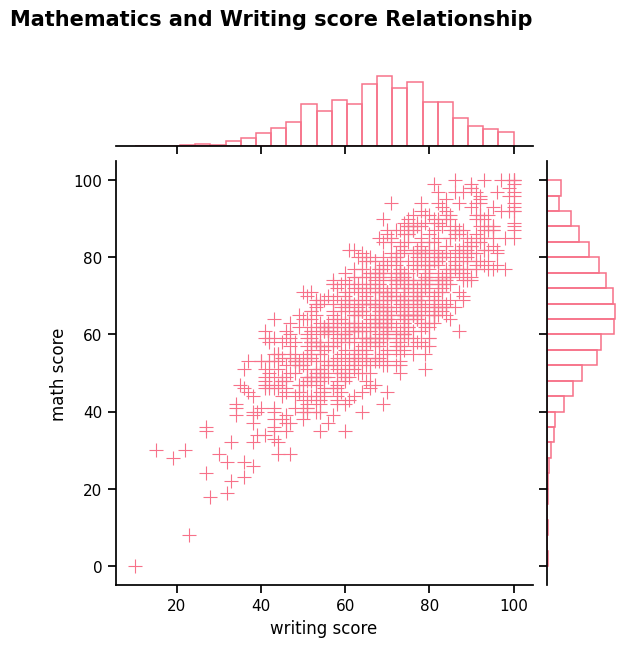

In [ ]:
sns.set_palette("husl", 9)
sns.jointplot(
    data=data, x="writing score", y="math score",
    marker="+", s=100, marginal_kws=dict(bins=25, fill=False),
)
plt.title('Mathematics and Writing score Relationship', fontsize=15, fontweight='bold',y=1.3,loc="right")
plt.show()

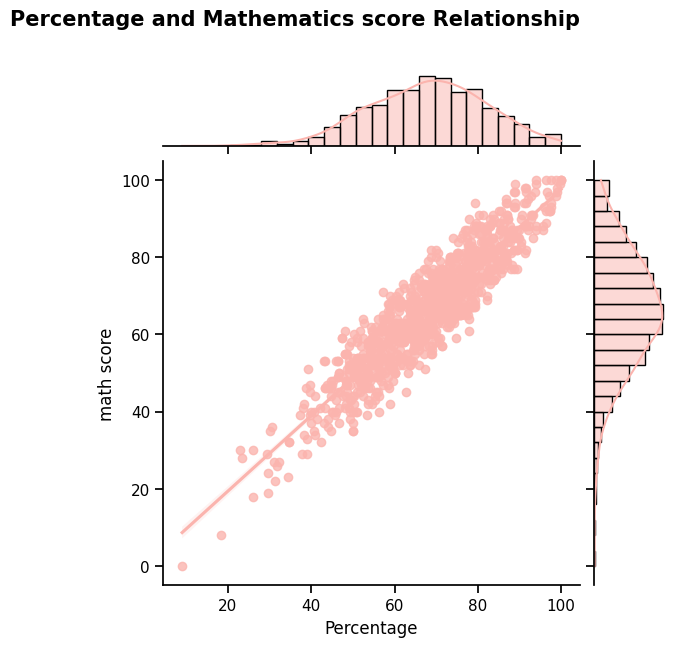

In [ ]:
# Percentage and Mathematics score Relationship
sns.set_palette("Pastel1")
sns.jointplot(data=data, x="Percentage", y="math score", kind="reg")
plt.title('Percentage and Mathematics score Relationship', fontsize=15, fontweight='bold',y=1.3,loc="right")
plt.show()

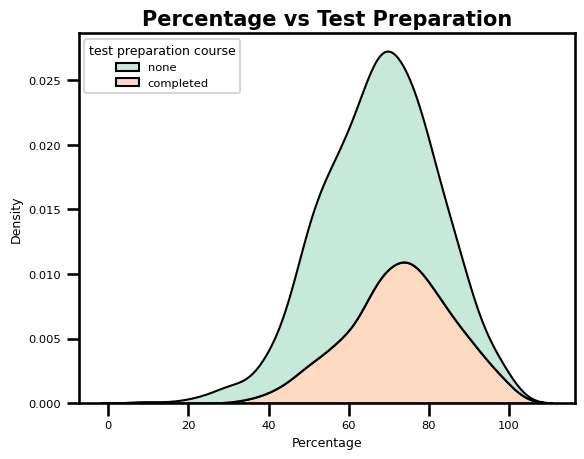

In [ ]:
sns.set_context("talk",font_scale=0.5)
sns.set_palette("Pastel2")
sns.kdeplot(data=data, x="Percentage", hue="test preparation course", multiple="stack")
plt.title('Percentage vs Test Preparation',fontsize=15, fontweight='bold')

plt.show()

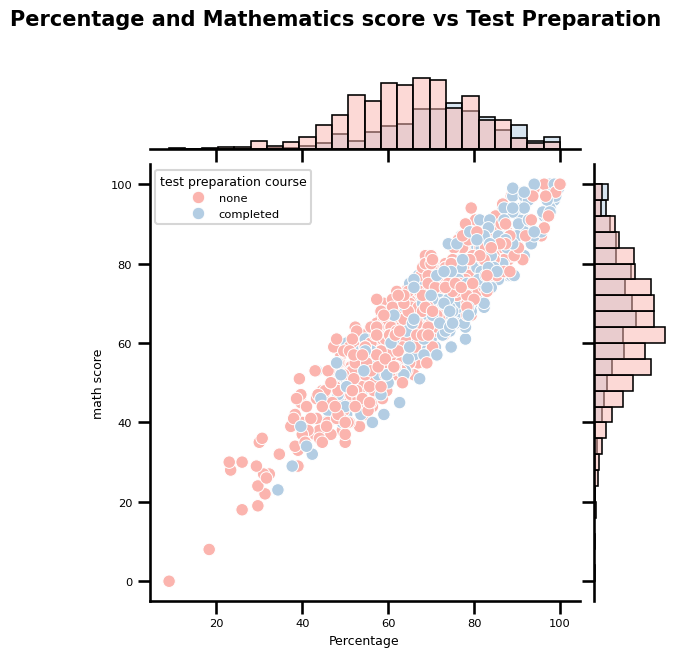

In [ ]:
sns.set_palette("Pastel1")
g = sns.JointGrid(data=data, x="Percentage", y="math score", hue="test preparation course")
g.plot(sns.scatterplot, sns.histplot)
plt.title('Percentage and Mathematics score vs Test Preparation ', fontsize=15, fontweight='bold',y=1.3,loc="right")
plt.show()

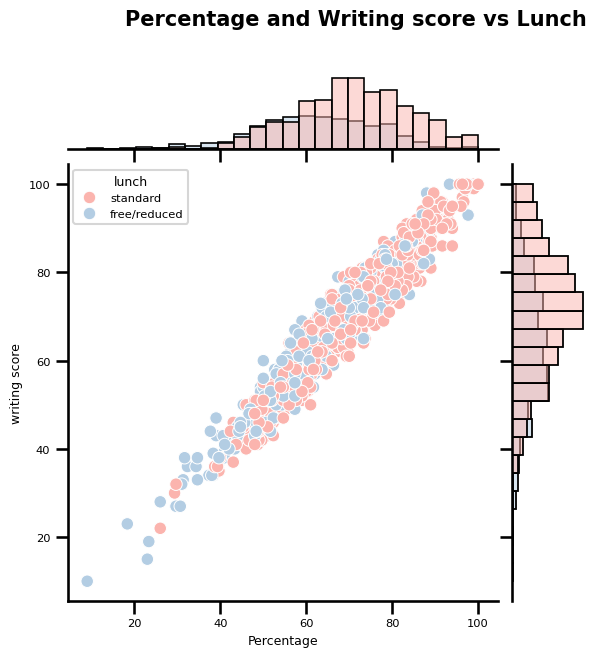

In [ ]:
sns.set_palette("Pastel1")
g = sns.JointGrid(data=data, x="Percentage", y="writing score", hue="lunch")
g.plot(sns.scatterplot, sns.histplot)
plt.title('Percentage and Writing score vs Lunch', fontsize=15, fontweight='bold',y=1.3,loc="right")
plt.show()

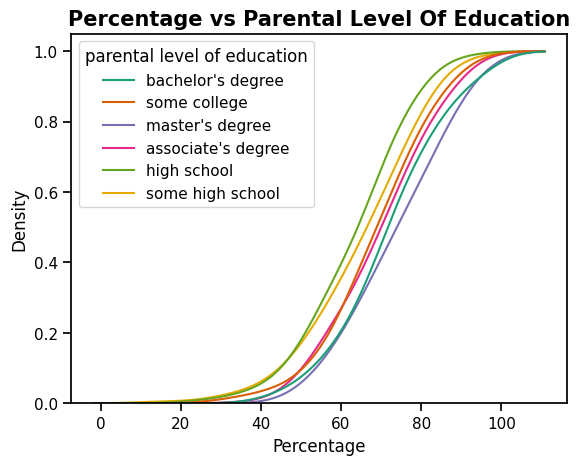

In [ ]:
sns.set_palette("Dark2")
sns.set_context("notebook",font_scale=1)
sns.kdeplot(
    data=data, x="Percentage", hue="parental level of education",
    cumulative=True, common_norm=False, common_grid=True,
)
plt.title('Percentage vs Parental Level Of Education',fontsize=15, fontweight='bold')

plt.show()

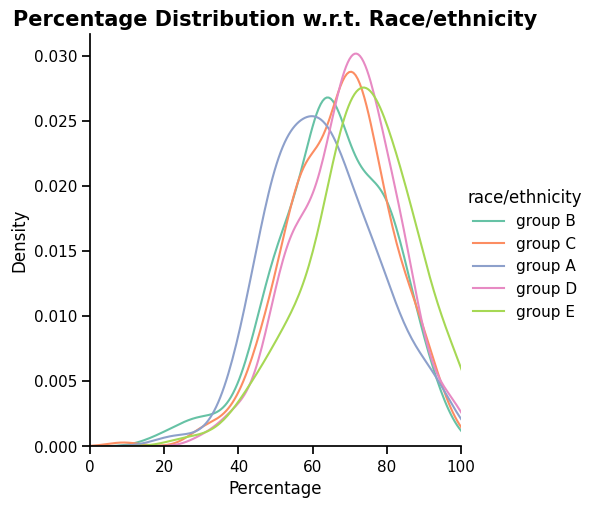

In [ ]:
sns.set_palette("Set2")
(sns.FacetGrid(data,hue="race/ethnicity", height=5,xlim = (0,100)).map(sns.kdeplot, "Percentage").add_legend())
plt.title('Percentage Distribution w.r.t. Race/ethnicity',fontsize=15, fontweight='bold')

plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder
lc = LabelEncoder()
data['gender'] = lc.fit_transform(data['gender'])
data['race/ethnicity'] = lc.fit_transform(data['race/ethnicity'])
data['parental level of education'] = lc.fit_transform(data['parental level of education'])
data['lunch'] = lc.fit_transform(data['lunch'])
data['test preparation course'] = lc.fit_transform(data['test preparation course'])
data['Grade'] = lc.fit_transform(data['Grade'])
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Percentage,Grade
0,0,1,1,1,1,72,72,74,72.666667,4
1,0,2,4,1,0,69,90,88,82.333333,2
2,0,1,3,1,1,90,95,93,92.666667,0
3,1,0,0,0,1,47,57,44,49.333333,6
4,1,2,4,1,1,76,78,75,76.333333,4


In [ ]:
data.corr()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Percentage,Grade
gender,1.000000,-0.001502,0.001913,0.021372,-0.006028,0.167982,-0.244313,-0.301225,-0.130861,0.108853
race/ethnicity,-0.001502,1.000000,-0.031946,0.046563,-0.017508,0.216415,0.145253,0.165691,0.185168,-0.122385
parental level of education,0.001913,-0.031946,1.000000,0.006320,-0.023968,-0.068279,-0.072444,-0.084299,-0.078883,0.062826
lunch,0.021372,0.046563,0.006320,1.000000,0.017044,0.350877,0.229560,0.245769,0.290064,-0.245524
test preparation course,-0.006028,-0.017508,-0.023968,0.017044,1.000000,-0.177702,-0.241780,-0.312946,-0.256710,0.218909
math score,0.167982,0.216415,-0.068279,0.350877,-0.177702,1.000000,0.817580,0.802642,0.918746,-0.762501
reading score,-0.244313,0.145253,-0.072444,0.229560,-0.241780,0.817580,1.000000,0.954598,0.970331,-0.804148
writing score,-0.301225,0.165691,-0.084299,0.245769,-0.312946,0.802642,0.954598,1.000000,0.965667,-0.805186
Percentage,-0.130861,0.185168,-0.078883,0.290064,-0.256710,0.918746,0.970331,0.965667,1.000000,-0.830869
Grade,0.108853,-0.122385,0.062826,-0.245524,0.218909,-0.762501,-0.804148,-0.805186,-0.830869,1.000000


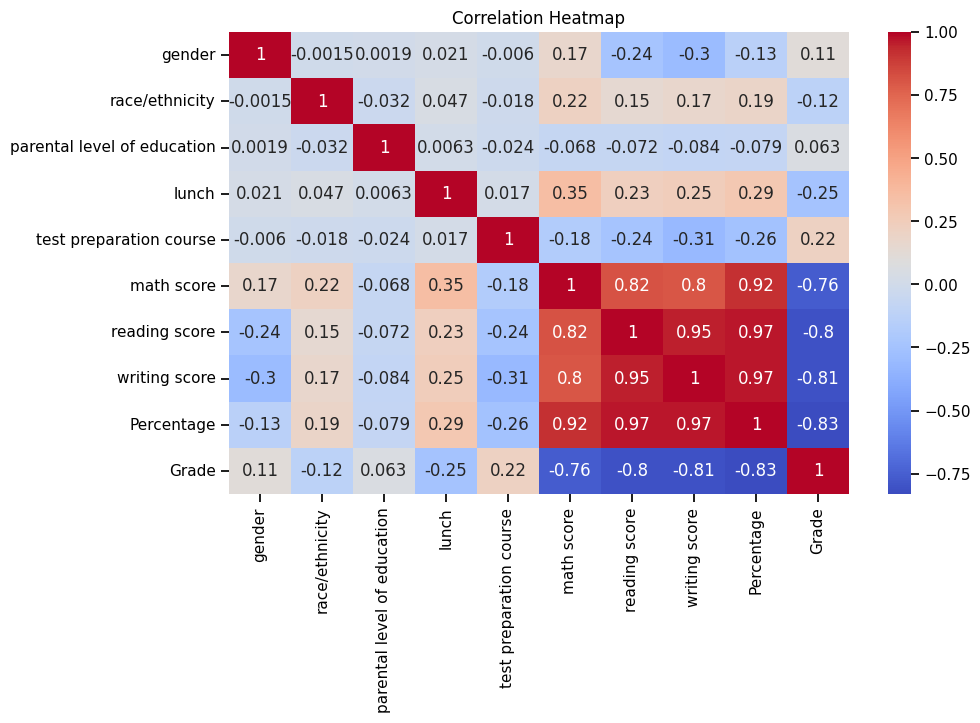

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Dataset Loaded Successfully!
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


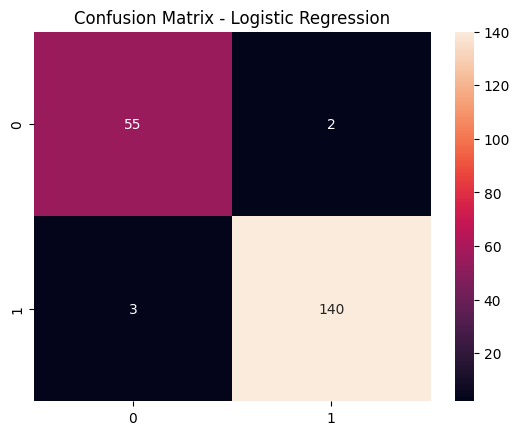

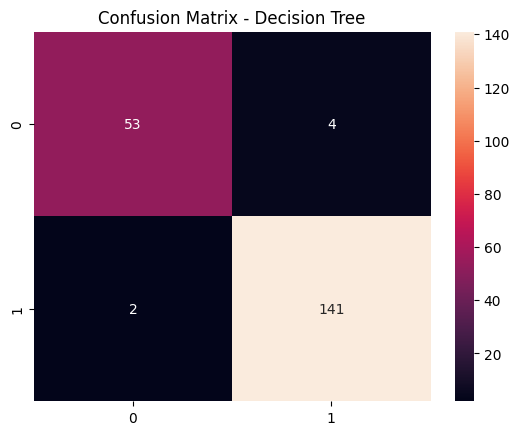

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7793 - loss: 0.5769 - val_accuracy: 0.9750 - val_loss: 0.3287
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9393 - loss: 0.2827 - val_accuracy: 1.0000 - val_loss: 0.1526
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9518 - loss: 0.1647 - val_accuracy: 0.9875 - val_loss: 0.0880
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9743 - loss: 0.1087 - val_accuracy: 1.0000 - val_loss: 0.0604
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9804 - loss: 0.0778 - val_accuracy: 0.9875 - val_loss: 0.0457
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9738 - loss: 0.0767 - val_accuracy: 1.0000 - val_loss: 0.0361
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9812 - loss: 0.0659 - val_accuracy: 1.0000 - val_loss: 0.0298
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9765 - loss: 0.0652 - val_accuracy: 1.0000 - val_loss

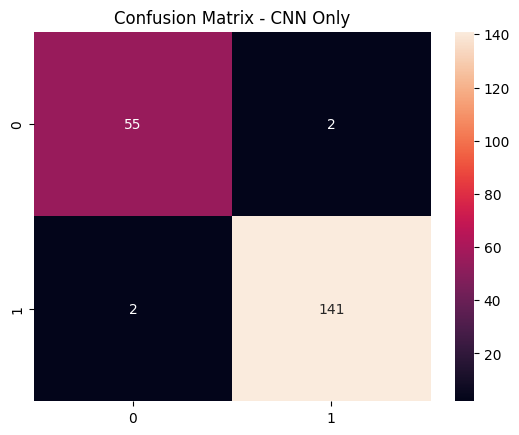

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.7608 - loss: 0.6261 - val_accuracy: 0.9375 - val_loss: 0.3846
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9058 - loss: 0.3293 - val_accuracy: 0.9375 - val_loss: 0.1937
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9537 - loss: 0.1798 - val_accuracy: 0.9625 - val_loss: 0.1083
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9569 - loss: 0.1018 - val_accuracy: 0.9750 - val_loss: 0.0711
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9690 - loss: 0.0835 - val_accuracy: 0.9625 - val_loss: 0.0537
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9721 - loss: 0.0704 - val_accuracy: 0.9750 - val_loss: 0.0788
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9593 - loss: 0.0792 - val_accuracy: 0.9875 - val_loss: 0.0559
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9794 - loss: 0.0627 - val_accuracy: 0.9750 - val_loss: 0.

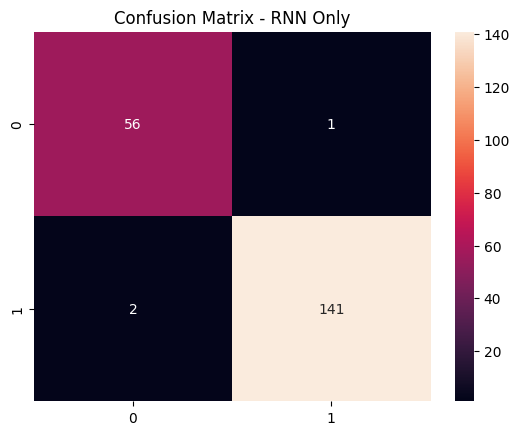

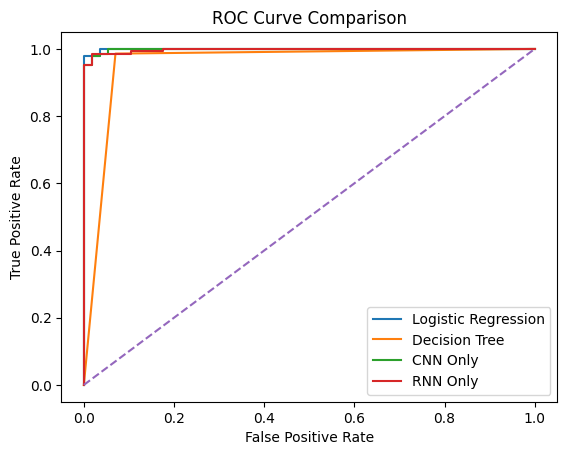


MODEL PERFORMANCE COMPARISON
                     Accuracy  Precision    Recall  F1 Score
Logistic Regression     0.975   0.985915  0.979021  0.982456
Decision Tree           0.970   0.972414  0.986014  0.979167
CNN Only                0.980   0.986014  0.986014  0.986014
RNN (GRU) Only          0.985   0.992958  0.986014  0.989474


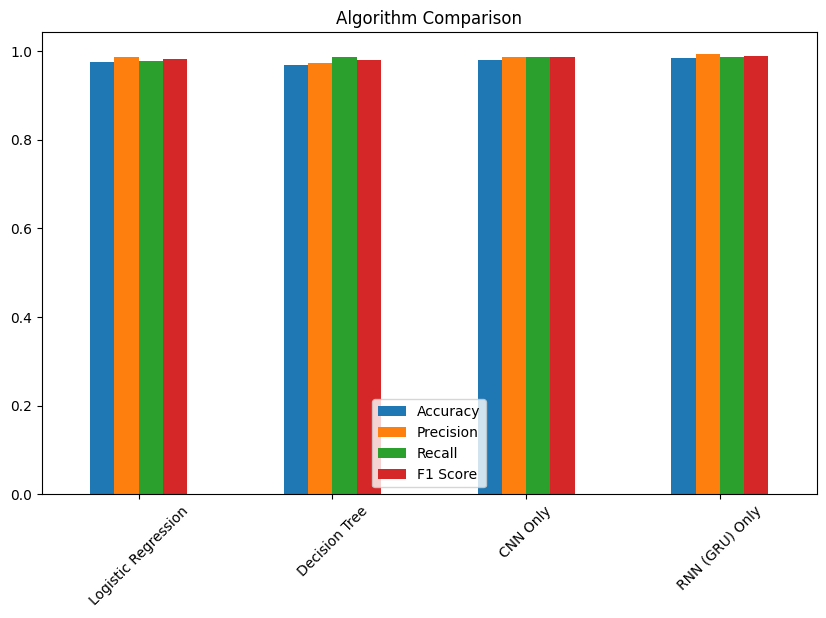

In [ ]:
# ======================================================
# 1. IMPORT LIBRARIES
# ======================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, GRU, Dense, Dropout, Flatten

# ======================================================
# 2. LOAD DATASET
# ======================================================
file_path = ('/content/StudentsPerformance (1).csv')
df = pd.read_csv(file_path)

print("Dataset Loaded Successfully!")
print(df.head())

# ======================================================
# 3. CREATE TARGET VARIABLE (High / Low Performance)
# ======================================================
df['average_score'] = (df['math score'] +
                       df['reading score'] +
                       df['writing score']) / 3

df['performance'] = np.where(df['average_score'] >= 60, 1, 0)
df.drop('average_score', axis=1, inplace=True)

# ======================================================
# 4. ENCODE CATEGORICAL VARIABLES
# ======================================================
le = LabelEncoder()
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])

# ======================================================
# 5. SPLIT FEATURES AND TARGET
# ======================================================
X = df.drop('performance', axis=1)
y = df['performance']

# ======================================================
# 6. NORMALIZATION
# ======================================================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ======================================================
# 7. TRAIN TEST SPLIT
# ======================================================
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# Dictionary to store results
results = {}

# ======================================================
# 8. LOGISTIC REGRESSION
# ======================================================
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

results["Logistic Regression"] = [
    accuracy_score(y_test, y_pred_lr),
    precision_score(y_test, y_pred_lr),
    recall_score(y_test, y_pred_lr),
    f1_score(y_test, y_pred_lr)
]

cm = confusion_matrix(y_test, y_pred_lr)
plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# ======================================================
# 9. DECISION TREE
# ======================================================
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

results["Decision Tree"] = [
    accuracy_score(y_test, y_pred_dt),
    precision_score(y_test, y_pred_dt),
    recall_score(y_test, y_pred_dt),
    f1_score(y_test, y_pred_dt)
]

cm = confusion_matrix(y_test, y_pred_dt)
plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix - Decision Tree")
plt.show()

# ======================================================
# 10. CNN ONLY MODEL
# ======================================================
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

cnn_model = Sequential()
cnn_model.add(Conv1D(64, 2, activation='relu',
                     input_shape=(X_train.shape[1],1)))
cnn_model.add(Flatten())
cnn_model.add(Dense(32, activation='relu'))
cnn_model.add(Dropout(0.3))
cnn_model.add(Dense(1, activation='sigmoid'))

cnn_model.compile(loss='binary_crossentropy',
                  optimizer='adam',
                  metrics=['accuracy'])

cnn_model.fit(X_train_cnn, y_train,
              epochs=20, batch_size=32,
              validation_split=0.1, verbose=1)

y_pred_prob_cnn = cnn_model.predict(X_test_cnn)
y_pred_cnn = (y_pred_prob_cnn > 0.5).astype(int)

results["CNN Only"] = [
    accuracy_score(y_test, y_pred_cnn),
    precision_score(y_test, y_pred_cnn),
    recall_score(y_test, y_pred_cnn),
    f1_score(y_test, y_pred_cnn)
]

cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix - CNN Only")
plt.show()

# ======================================================
# 11. RNN (GRU) ONLY MODEL
# ======================================================
rnn_model = Sequential()
rnn_model.add(GRU(64,
                  input_shape=(X_train.shape[1],1)))
rnn_model.add(Dropout(0.3))
rnn_model.add(Dense(32, activation='relu'))
rnn_model.add(Dense(1, activation='sigmoid'))

rnn_model.compile(loss='binary_crossentropy',
                  optimizer='adam',
                  metrics=['accuracy'])

rnn_model.fit(X_train_cnn, y_train,
              epochs=20, batch_size=32,
              validation_split=0.1, verbose=1)

y_pred_prob_rnn = rnn_model.predict(X_test_cnn)
y_pred_rnn = (y_pred_prob_rnn > 0.5).astype(int)

results["RNN (GRU) Only"] = [
    accuracy_score(y_test, y_pred_rnn),
    precision_score(y_test, y_pred_rnn),
    recall_score(y_test, y_pred_rnn),
    f1_score(y_test, y_pred_rnn)
]

cm = confusion_matrix(y_test, y_pred_rnn)
plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix - RNN Only")
plt.show()

# ======================================================
# 12. ROC CURVE COMPARISON
# ======================================================
plt.figure()

# Logistic Regression ROC
y_prob_lr = lr.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, y_prob_lr)
plt.plot(fpr, tpr, label="Logistic Regression")

# Decision Tree ROC
y_prob_dt = dt.predict_proba(X_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, y_prob_dt)
plt.plot(fpr, tpr, label="Decision Tree")

# CNN ROC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob_cnn)
plt.plot(fpr, tpr, label="CNN Only")

# RNN ROC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob_rnn)
plt.plot(fpr, tpr, label="RNN Only")

plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

# ======================================================
# 13. MODEL COMPARISON TABLE
# ======================================================
results_df = pd.DataFrame(results,
                          index=["Accuracy",
                                 "Precision",
                                 "Recall",
                                 "F1 Score"]).T

print("\nMODEL PERFORMANCE COMPARISON")
print(results_df)

results_df.plot(kind='bar', figsize=(10,6))
plt.title("Algorithm Comparison")
plt.xticks(rotation=45)
plt.show()